# Asistente de inventario · Análisis de datos y EDA
**Optativa III – Agentes Inteligentes**

Este notebook hace **todo el análisis en un solo archivo**: limpia los datos reales de MercadoLibre, los explora (EDA), crea las variables que el dataset no trae (stock, empaque, proveedores) y calcula qué productos se están agotando, cuánto pedir y qué proveedor recomendar.

**Cómo usarlo:** deja `muestra_meli.csv` en la misma carpeta que este notebook y ejecuta las celdas en orden (**Run All**). Al final crea la carpeta `salida/` con los archivos para cargar a MongoDB.

**Índice:** 1 Parámetros · 2 Carga · 3 Limpieza · 4 EDA · 5 Demanda diaria · 6 Variables creadas · 7 Productos críticos · 8 Cotización · 9 Guardar y revisar

## 1. Parámetros
Todo lo que puedes querer cambiar está aquí, y solo aquí. **Para qué:** si el dueño cambia un valor (la tasa, los días de cobertura), se recalcula todo sin tocar el resto.

In [44]:
%pip install numpy pandas matplotlib


[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [45]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ARCHIVO_ENTRADA = Path("muestra_meli.csv")
CARPETA_SALIDA = Path("salida")

TASA_MXN_COP = 169.5     # pesos colombianos por 1 peso mexicano (tasa fija del 28-oct-2026)
VENTANA_DIAS = 30        # días recientes con los que se calcula la demanda diaria
DIAS_SEGURIDAD = 2       # colchón para el punto de reorden
DIAS_COBERTURA = 14      # para cuántos días queremos dejar surtido el producto
PLAZO_POR_DEFECTO = 5    # plazo que se usa si un producto no tiene proveedor
UMBRAL_ATIPICO = 3       # un día es atípico si supera Q3 + 3 * (Q3 - Q1) de su producto
SEMILLA = 42             # hace que los datos creados al azar sean siempre los mismos

CARPETA_SALIDA.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

def cop(valor):
    # Formato de pesos colombianos: 1234567 -> $1.234.567
    return "$" + f"{valor:,.0f}".replace(",", ".")

## 2. Carga y revisión inicial
**Qué hago:** leer el archivo y comprobar que está completo. **Para qué:** si faltan días o hay vacíos, los resultados posteriores no serían confiables.

In [46]:
df = pd.read_csv("/Users/lauramayerlydiazboada/Asistente-inventario-/data/muestra_meli.csv", parse_dates=["date"])
print("Filas y columnas:", df.shape)
print("Rango de fechas:", df["date"].min().date(), "a", df["date"].max().date())
print("Productos:", df["sku"].nunique(), "| Días distintos:", df["date"].nunique())
print("Filas por producto (debe ser 59 en todos):", df.groupby("sku").size().unique())
print("Valores vacíos en total:", int(df.isna().sum().sum()))
df.head(3)

Filas y columnas: (2950, 12)
Rango de fechas: 2021-02-01 a 2021-03-31
Productos: 50 | Días distintos: 59
Filas por producto (debe ser 59 en todos): [59]
Valores vacíos en total: 0


,sku,date,sold_quantity,current_price,currency,listing_type,shipping_logistic_type,shipping_payment,minutes_active,item_title,item_domain_id,site_id
0,575480,2021-02-01,4,43.2,MEX,classic,fulfillment,paid_shipping,1440.0,Funda Brazo Protector Deportiva Celular Ejerci...,MLM-CELLPHONE_COVERS,MLM
1,575480,2021-02-02,9,43.2,MEX,classic,fulfillment,paid_shipping,1440.0,Funda Brazo Protector Deportiva Celular Ejerci...,MLM-CELLPHONE_COVERS,MLM
2,575480,2021-02-03,5,43.2,MEX,classic,fulfillment,paid_shipping,1440.0,Funda Brazo Protector Deportiva Celular Ejerci...,MLM-CELLPHONE_COVERS,MLM


**Resultado:** 50 productos × 59 días = 2.950 filas, sin vacíos y sin días faltantes. No hay que rellenar ni descartar nada.

## 3. Limpieza y transformación
Cada paso indica **qué cambia y por qué**.

### 3.1 Nombres de columnas y valores en español
| Antes | Después |
|---|---|
| `date`, `sold_quantity`, `current_price`, `minutes_active` | `fecha`, `cantidad_vendida`, `precio_mxn`, `minutos_activos` |
| `item_title`, `item_domain_id`, `site_id` | `titulo_producto`, `categoria`, `pais` |
| `MLM` · `MLM-CELLPHONE_COVERS` | `México` · `Fundas para celular` |

**Para qué:** que todo el proyecto (MongoDB, grafo, Telegram) use los mismos nombres y se entienda sin diccionario.

In [47]:
df = df.rename(columns={
    "date": "fecha",
    "sold_quantity": "cantidad_vendida",
    "current_price": "precio_mxn",      # el precio original viene en pesos mexicanos
    "minutes_active": "minutos_activos",
    "item_title": "titulo_producto",
    "item_domain_id": "categoria",
    "site_id": "pais",
})
df["pais"] = df["pais"].map({"MLM": "México"})
df["categoria"] = df["categoria"].map({"MLM-CELLPHONE_COVERS": "Fundas para celular"})
assert df["pais"].notna().all() and df["categoria"].notna().all(), "Hay valores sin traducir"
df[["sku", "fecha", "cantidad_vendida", "precio_mxn", "pais", "categoria"]].head(3)

,sku,fecha,cantidad_vendida,precio_mxn,pais,categoria
0,575480,2021-02-01,4,43.2,México,Fundas para celular
1,575480,2021-02-02,9,43.2,México,Fundas para celular
2,575480,2021-02-03,5,43.2,México,Fundas para celular


### 3.2 Moneda: de pesos mexicanos a pesos colombianos
El código `MEX` del dataset es el peso mexicano. Como **todas** las filas están en esa moneda, basta **una sola tasa**: `precio_cop = precio_mxn × tasa`.

**Tasa fija usada: 1 MXN = 169,5 COP** (valor del 28-oct-2026; las fuentes consultadas daban entre 168,5 y 170). Se cambia en la celda de parámetros.

In [48]:
assert (df["currency"] == "MEX").all(), "Hay una moneda distinta de MEX: no se puede usar una sola tasa"
df["precio_cop"] = (df["precio_mxn"] * TASA_MXN_COP).round(0).astype(int)
print(f"Tasa usada: 1 MXN = {TASA_MXN_COP} COP")
print("Ejemplo:", df["precio_mxn"].min(), "MXN =", cop(df["precio_cop"].min()), "COP")
print("Ejemplo:", df["precio_mxn"].max(), "MXN =", cop(df["precio_cop"].max()), "COP")

Tasa usada: 1 MXN = 169.5 COP
Ejemplo: 29.0 MXN = $4.916 COP
Ejemplo: 417.5 MXN = $70.766 COP


### 3.3 Columnas que descarto
`listing_type`, `shipping_logistic_type`, `shipping_payment` y `currency`.

**Por qué:** describen cómo vende MercadoLibre (tipo de publicación, envío) y el agente no las usa; la moneda ya la usamos y es igual en todas las filas. Menos columnas = análisis más claro y defensa más fácil.

In [49]:
df = df.drop(columns=["listing_type", "shipping_logistic_type", "shipping_payment", "currency"])
print("Columnas que quedan:", list(df.columns))

Columnas que quedan: ['sku', 'fecha', 'cantidad_vendida', 'precio_mxn', 'minutos_activos', 'titulo_producto', 'categoria', 'pais', 'precio_cop']


### 3.4 Días activos (de `minutos_activos`)
`minutos_activos` dice cuánto tiempo estuvo publicado el producto ese día (1440 = día completo). Lo convierto a fracción de día: `dias_activos = minutos / 1440`.

**Por qué:** un día con 0 minutos activos **no es demanda cero**, es que el producto no se podía comprar. Más abajo lo usamos para no subestimar la demanda.

In [50]:
df["dias_activos"] = (df["minutos_activos"] / 1440).round(3)
df = df.sort_values(["sku", "fecha"]).reset_index(drop=True)
df[["sku", "fecha", "minutos_activos", "dias_activos"]].head(3)

,sku,fecha,minutos_activos,dias_activos
0,12097,2021-02-01,1440.0,1.0
1,12097,2021-02-02,1440.0,1.0
2,12097,2021-02-03,1440.0,1.0


## 4. Análisis exploratorio (EDA)
### 4.1 Ventas por día

count    2950.00
mean        6.05
std         6.06
min         0.00
25%         2.00
50%         5.00
75%         8.00
max       126.00
Name: cantidad_vendida, dtype: float64

Días con cero ventas (producto-día): 12.5%


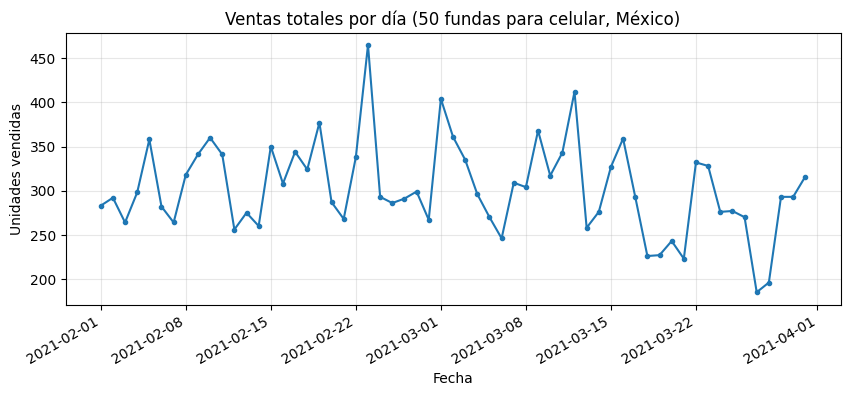

In [51]:
print(df["cantidad_vendida"].describe().round(2))
print(f"\nDías con cero ventas (producto-día): {(df['cantidad_vendida'] == 0).mean():.1%}")

total_dia = df.groupby("fecha")["cantidad_vendida"].sum()
fig, ax = plt.subplots()
ax.plot(total_dia.index, total_dia.values, marker="o", markersize=3)
ax.set_title("Ventas totales por día (50 fundas para celular, México)")
ax.set_xlabel("Fecha"); ax.set_ylabel("Unidades vendidas")
fig.autofmt_xdate(); plt.show()

**Lectura:** cada producto vende en promedio unas 6 unidades por día (la mitad vende 5 o menos). Las ventas totales se mueven entre 185 y 465 unidades diarias, sin una tendencia fuerte: es una demanda **estable**, buena para una fórmula simple.

### 4.2 Ventas por producto

count     50.0
mean     357.0
std      122.6
min      249.0
25%      269.0
50%      316.0
75%      388.8
max      837.0
Name: cantidad_vendida, dtype: float64


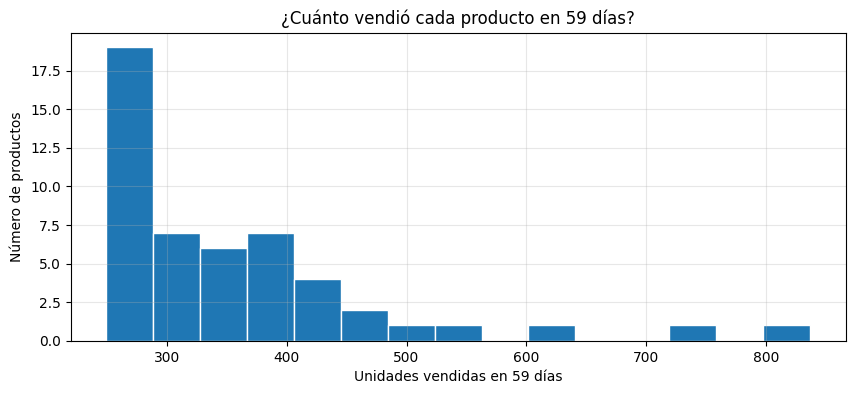

In [52]:
ventas_producto = df.groupby("sku")["cantidad_vendida"].sum()
print(ventas_producto.describe().round(1))

fig, ax = plt.subplots()
ax.hist(ventas_producto, bins=15, edgecolor="white")
ax.set_title("¿Cuánto vendió cada producto en 59 días?")
ax.set_xlabel("Unidades vendidas en 59 días"); ax.set_ylabel("Número de productos")
plt.show()

**Lectura:** la mayoría vende entre 250 y 390 unidades en los 59 días; unos pocos venden mucho más. Ningún producto vende casi nada: todos sirven para probar la reposición.

### 4.3 Ventas por día de la semana

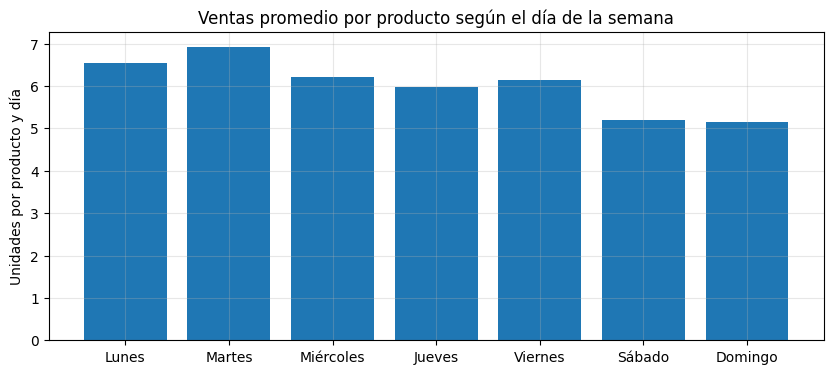

In [53]:
nombres_dia = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
por_dia = df.groupby(df["fecha"].dt.dayofweek)["cantidad_vendida"].mean()

fig, ax = plt.subplots()
ax.bar(nombres_dia, por_dia.values)
ax.set_title("Ventas promedio por producto según el día de la semana")
ax.set_ylabel("Unidades por producto y día")
plt.show()

**Lectura:** se vende un poco más de lunes a viernes que el sábado y el domingo, pero la diferencia es pequeña. **Decisión:** no modelo estacionalidad semanal; con 59 días de datos no justificaría la complejidad.

### 4.4 Precios

       precio_mxn  precio_cop
count      2950.0      2950.0
mean        132.0     22335.0
std         106.0     18045.0
min          29.0      4916.0
25%          59.0     10000.0
50%          65.0     11018.0
75%         199.0     33730.0
max         418.0     70766.0

Productos que cambiaron de precio en algún momento: 30 de 50


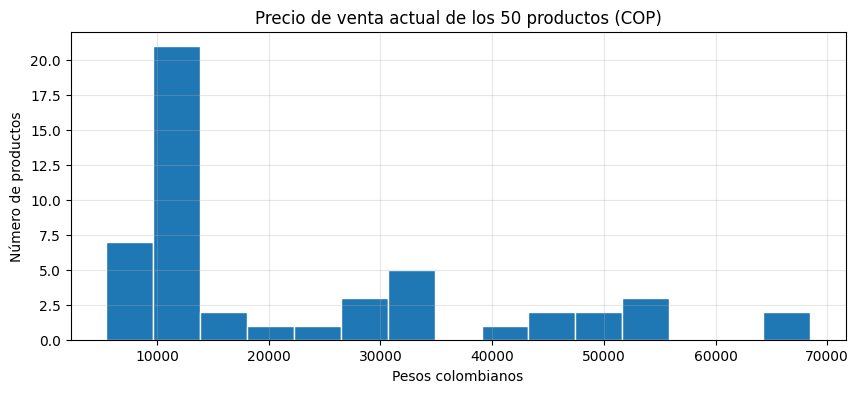

In [54]:
ultimo_precio = df.sort_values("fecha").groupby("sku")["precio_cop"].last()
cambios = (df.groupby("sku")["precio_mxn"].nunique() > 1).sum()
print(df[["precio_mxn", "precio_cop"]].describe().round(0))
print(f"\nProductos que cambiaron de precio en algún momento: {cambios} de {df['sku'].nunique()}")

fig, ax = plt.subplots()
ax.hist(ultimo_precio, bins=15, edgecolor="white")
ax.set_title("Precio de venta actual de los 50 productos (COP)")
ax.set_xlabel("Pesos colombianos"); ax.set_ylabel("Número de productos")
plt.show()

**Lectura:** hay dos grupos: fundas baratas (cerca de 10.000 a 12.000 COP) y fundas de gama alta (de 30.000 a 70.000 COP). Como 30 productos cambiaron de precio, **uso el precio del último día** como precio actual.

### 4.5 Días sin publicar

In [55]:
df["estado_publicacion"] = pd.cut(df["minutos_activos"], bins=[-1, 0, 1439, 1440],
                                  labels=["No publicado (0 min)", "Parcial", "Día completo"])
resumen_estado = df.groupby("estado_publicacion", observed=True)["cantidad_vendida"].agg(
    filas="size", ventas_promedio="mean", ventas_totales="sum").round(2)
print(resumen_estado)
print("\nProductos con al menos un día sin publicar:",
      df[df["minutos_activos"] == 0]["sku"].nunique(), "de", df["sku"].nunique())

                      filas  ventas_promedio  ventas_totales
estado_publicacion                                          
No publicado (0 min)    259             0.00               0
Parcial                 139             4.37             608
Día completo           2552             6.76           17244

Productos con al menos un día sin publicar: 29 de 50


**Lectura:** en los días **sin publicar** la venta es siempre 0 (no se podía comprar). Si tratáramos esos ceros como "nadie quiso comprar", la demanda saldría más baja de lo real y el agente pediría de menos. Por eso en la sección 5 calculo una demanda **ajustada**.

### 4.6 Días atípicos (picos de ventas)
**Qué hago:** marcar, **sin borrar**, los días en que un producto vende muy por encima de lo normal (más de Q3 + 3×(Q3−Q1) de ese producto). **Por qué no borrar:** pueden ser promociones reales; lo decidimos con el dueño.

In [56]:
def marcar_atipicos(ventas):
    q1, q3 = ventas.quantile([0.25, 0.75])
    return ventas > q3 + UMBRAL_ATIPICO * (q3 - q1)

df["dia_atipico"] = df.groupby("sku")["cantidad_vendida"].transform(marcar_atipicos)
print("Días atípicos:", int(df["dia_atipico"].sum()), "en", df[df["dia_atipico"]]["sku"].nunique(), "productos")
df[df["dia_atipico"]].nlargest(5, "cantidad_vendida")[["sku", "fecha", "cantidad_vendida"]]

Días atípicos: 17 en 14 productos


,sku,fecha,cantidad_vendida
2654,623897,2021-03-31,126
317,66262,2021-02-23,110
726,160058,2021-02-19,82
1951,439339,2021-02-05,68
161,22919,2021-03-16,40


**Lectura:** son pocos (17 de 2.950 filas). El más grande es de 126 unidades el último día del periodo, y pesa en la demanda reciente de ese producto. Quedan **dentro** y marcados.

## 5. Demanda diaria por producto
Tomo los últimos 30 días (1 al 31 de marzo de 2021; ese último día es nuestro "hoy") y calculo dos versiones:

- **Simple:** ventas ÷ días del calendario. Es la fórmula tal cual de la guía.
- **Ajustada:** ventas ÷ días en que el producto estuvo **realmente publicado**. **Es la que usa el agente.**

Ventana usada: 2021-03-02 a 2021-03-31
       demanda_diaria_simple  demanda_diaria
count                  50.00           50.00
mean                    5.84            6.96
std                     2.48            2.94
min                     2.20            3.67
25%                     4.08            5.11
50%                     5.36            6.24
75%                     7.02            8.02
max                    15.37           18.73


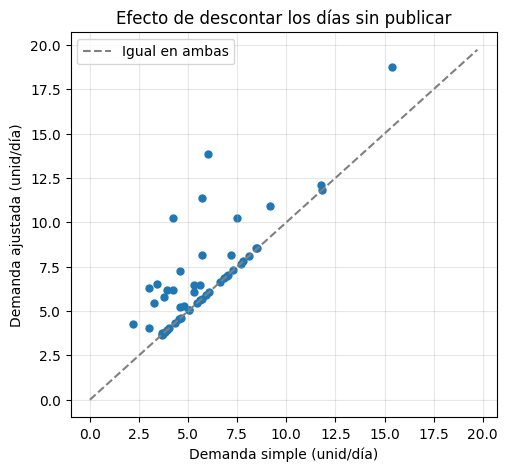

In [57]:
fecha_fin = df["fecha"].max()
ventana = df[df["fecha"] > fecha_fin - pd.Timedelta(days=VENTANA_DIAS)]
g = ventana.groupby("sku")
assert (g["dias_activos"].sum() > 0).all(), "Un producto no estuvo publicado en toda la ventana"

demanda = pd.DataFrame({
    "demanda_diaria_simple": g["cantidad_vendida"].sum() / g["fecha"].nunique(),
    "demanda_diaria": g["cantidad_vendida"].sum() / g["dias_activos"].sum(),
}).round(2)

print("Ventana usada:", ventana["fecha"].min().date(), "a", fecha_fin.date())
print(demanda.describe().round(2))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(demanda["demanda_diaria_simple"], demanda["demanda_diaria"], s=25)
tope = demanda.max().max() + 1
ax.plot([0, tope], [0, tope], "--", color="gray", label="Igual en ambas")
ax.set_xlabel("Demanda simple (unid/día)"); ax.set_ylabel("Demanda ajustada (unid/día)")
ax.set_title("Efecto de descontar los días sin publicar"); ax.legend()
plt.show()

**Lectura:** los puntos **por encima de la línea** son productos que estuvieron varios días sin publicar: su demanda real es mayor que la simple. En promedio sube de 5,8 a 7,0 unidades por día. Usar la simple haría que el agente pidiera de menos.

## 6. Variables que el dataset no trae (las creamos)
El dataset trae ventas reales, pero no stock, empaques ni proveedores. Los creamos con **valores al azar controlados** (semilla fija: salen siempre iguales). Son **supuestos** y así se declaran en la defensa.

### 6.1 Tabla base de productos

In [58]:
ultimo = df[df["fecha"] == fecha_fin].set_index("sku")
productos = pd.DataFrame({
    "titulo_producto": ultimo["titulo_producto"],
    "categoria": ultimo["categoria"],
    "pais": ultimo["pais"],
    "ventas_totales_59d": df.groupby("sku")["cantidad_vendida"].sum(),
    "dias_con_venta": (df["cantidad_vendida"] > 0).groupby(df["sku"]).sum(),
    "dias_sin_publicar": (df["minutos_activos"] == 0).groupby(df["sku"]).sum(),
    "dias_atipicos": df.groupby("sku")["dia_atipico"].sum(),
    "precio_mxn_actual": ultimo["precio_mxn"],
    "precio_cop_actual": ultimo["precio_cop"],
    "cambio_de_precio": df.groupby("sku")["precio_mxn"].nunique() > 1,
}).join(demanda)
print(productos.shape)
productos[["titulo_producto", "ventas_totales_59d", "demanda_diaria", "precio_cop_actual"]].head(5)

(50, 12)


,titulo_producto,ventas_totales_59d,demanda_diaria,precio_cop_actual
sku,,,,
12097,Funda Contra Agua Sumergible Protector Univers...,366,8.10,5424
15084,Carcasa Protector Supcase Ubstyle P/iPhone X 1...,289,4.63,52909
22919,Funda Impermeable De Celular Universal Bolsa C...,356,8.17,6610
25663,Funda Protectora Ipx8 Para Celular Contra Agua...,249,6.17,15086
43644,Case Acrigel iPhone Airbag Transparente iPhone...,465,10.26,11018


### 6.2 Stock actual, stock diario, empaque y mínimo manual
- **Stock actual:** días que le alcanzan al producto hoy (entre 1 y 25, al azar) × su demanda diaria. Así algunos quedan críticos y otros no.
- **Stock diario:** lo reconstruyo hacia atrás: `stock inicial = stock actual + ventas de los 59 días`, y cada día se resta lo vendido. Así el producto **realmente se va agotando** con las ventas reales, y el último día coincide con el stock actual.
- **Empaque:** 6, 12 o 24 unidades.
- **Mínimo manual:** igual al empaque (se usaría solo en productos sin historial).
- **Pedidos en camino:** 0 (simplificación).
- Un producto lo dejo **sin proveedor a propósito**, con poco stock, para probar esa ruta del grafo.

In [59]:
rng = np.random.default_rng(SEMILLA)
skus = productos.index.to_numpy()

dias_de_stock_hoy = rng.integers(1, 26, size=len(skus))
sku_sin_proveedor = int(rng.choice(skus))
dias_de_stock_hoy[list(skus).index(sku_sin_proveedor)] = 2   # será crítico seguro

productos["stock_actual"] = np.ceil(productos["demanda_diaria"] * dias_de_stock_hoy).astype(int)
productos["empaque"] = rng.choice([6, 12, 24], size=len(skus))
productos["minimo_manual"] = productos["empaque"]
productos["pedidos_en_camino"] = 0

# Stock diario reconstruido con las ventas reales
df = df.join(productos[["stock_actual"]], on="sku")
df["ventas_acumuladas"] = df.groupby("sku")["cantidad_vendida"].cumsum()
ventas_59d = df["sku"].map(productos["ventas_totales_59d"])
df["stock_estimado"] = df["stock_actual"] + ventas_59d - df["ventas_acumuladas"]
assert (df[df["fecha"] == fecha_fin].set_index("sku")["stock_estimado"] == productos["stock_actual"]).all()

print("Producto sin proveedor (a propósito):", sku_sin_proveedor)
productos[["stock_actual", "empaque", "minimo_manual", "pedidos_en_camino"]].describe().round(1)

Producto sin proveedor (a propósito): 486884


,stock_actual,empaque,minimo_manual,pedidos_en_camino
count,50.0,50.0,50.0,50.0
mean,86.8,14.8,14.8,0.0
std,44.5,7.7,7.7,0.0
min,13.0,6.0,6.0,0.0
25%,42.8,6.0,6.0,0.0
50%,85.0,12.0,12.0,0.0
75%,118.2,24.0,24.0,0.0
max,172.0,24.0,24.0,0.0


### 6.3 Proveedores y catálogo
Tres proveedores **ficticios** con una lógica clara: el más rápido es el más caro y el más lento es el más barato pero exige pedidos más grandes. Así hay que elegir de verdad.

| Proveedor | Plazo | Cobra (% del precio de venta) | Pedido mínimo |
|---|---|---|---|
| Distribuidora Andina | 2 días | 78 % | 1 empaque |
| Importadora Pacífico | 4 días | 70 % | 2 empaques |
| Mayorista Central | 7 días | 62 % | 4 empaques |

No todos tienen todos los productos: cada producto lo surten 1 a 3 proveedores, y el producto sin proveedor no aparece en el catálogo. El precio de cada uno tiene una pequeña variación (±5 %) para que no sean idénticos.

In [60]:
proveedores = pd.DataFrame({
    "proveedor": ["Distribuidora Andina", "Importadora Pacífico", "Mayorista Central"],
    "contacto": ["pedidos@distribuidoraandina.example", "ventas@importadorapacifico.example",
                 "compras@mayoristacentral.example"],
    "plazo_dias": [2, 4, 7],
    "factor_precio": [0.78, 0.70, 0.62],
    "empaques_minimos": [1, 2, 4],
})
prob_tiene = [0.90, 0.70, 0.60]   # probabilidad de que cada proveedor surta un producto

filas = []
for sku in skus:
    if sku == sku_sin_proveedor:
        continue
    tiene = [rng.random() < p for p in prob_tiene]
    if not any(tiene):
        tiene[0] = True            # todo producto (salvo el elegido) tiene al menos un proveedor
    for i, surte in enumerate(tiene):
        if surte:
            prov = proveedores.iloc[i]
            precio = productos.loc[sku, "precio_cop_actual"] * prov["factor_precio"] * rng.uniform(0.95, 1.05)
            filas.append({
                "sku": sku,
                "proveedor": prov["proveedor"],
                "precio_unitario_cop": int(round(precio, -1)),
                "plazo_dias": int(prov["plazo_dias"]),
                "pedido_minimo_unidades": int(productos.loc[sku, "empaque"] * prov["empaques_minimos"]),
            })
catalogo = pd.DataFrame(filas)
print("Filas del catálogo:", len(catalogo), "| Productos con proveedor:", catalogo["sku"].nunique())
print(catalogo.groupby("proveedor")["sku"].nunique())
catalogo.head(6)

Filas del catálogo: 115 | Productos con proveedor: 49
proveedor
Distribuidora Andina    45
Importadora Pacífico    37
Mayorista Central       33
Name: sku, dtype: int64


,sku,proveedor,precio_unitario_cop,plazo_dias,pedido_minimo_unidades
0,12097,Distribuidora Andina,4320,2,6
1,15084,Distribuidora Andina,39780,2,12
2,15084,Importadora Pacífico,35610,4,24
3,15084,Mayorista Central,33360,7,48
4,22919,Distribuidora Andina,5230,2,12
5,22919,Importadora Pacífico,4650,4,24


## 7. Productos críticos (fórmula del Anexo D de la guía)
Para cada producto:

1. `stock disponible = stock actual + pedidos en camino`
2. `punto de reorden = demanda diaria × (plazo + días de seguridad)`
3. **Es crítico si** `stock disponible ≤ punto de reorden`

**Qué plazo uso para detectar:** el **más largo** entre los proveedores que surten ese producto, para no enterarnos tarde (criterio prudente). Si no tiene proveedor, uso el plazo por defecto.

In [61]:
plazo_max = catalogo.groupby("sku")["plazo_dias"].max()
productos["plazo_referencia"] = productos.index.map(plazo_max)
productos["plazo_referencia"] = productos["plazo_referencia"].fillna(PLAZO_POR_DEFECTO)

productos["stock_disponible"] = productos["stock_actual"] + productos["pedidos_en_camino"]
productos["punto_reorden"] = (productos["demanda_diaria"] * (productos["plazo_referencia"] + DIAS_SEGURIDAD)).round(1)
productos["dias_de_stock"] = (productos["stock_disponible"] / productos["demanda_diaria"]).round(1)
productos["es_critico"] = productos["stock_disponible"] <= productos["punto_reorden"]
productos["tiene_proveedor"] = productos.index.isin(catalogo["sku"])

print("Productos críticos:", int(productos["es_critico"].sum()), "de", len(productos))
print("Críticos sin proveedor:", int((productos["es_critico"] & ~productos["tiene_proveedor"]).sum()))
productos[productos["es_critico"]].sort_values("dias_de_stock")[
    ["titulo_producto", "stock_actual", "demanda_diaria", "punto_reorden", "dias_de_stock"]].head(8)

Productos críticos: 12 de 50
Críticos sin proveedor: 1


,titulo_producto,stock_actual,demanda_diaria,punto_reorden,dias_de_stock
sku,,,,,
623897,Funda Impermeable De Celular Universal Bolsa C...,38,18.73,168.6,2.0
463257,Funda Bolsa Contra Agua Universal Celulares 6....,18,8.53,76.8,2.1
486884,Funda Protectora Supcase Minimalista Para iPho...,14,6.63,46.4,2.1
78136,Funda Samsung Galaxy A21s Transparente Con Cri...,13,4.27,38.4,3.0
92972,Funda Acrigel Samsung Galaxy iPhone Huawei Xia...,31,10.25,92.2,3.0
12097,Funda Contra Agua Sumergible Protector Univers...,25,8.10,32.4,3.1
428084,Funda Contra Agua Sumergible Protector Univers...,36,11.80,70.8,3.1
240902,Funda Xiaomi Poco X3 Nfc Piel Sintetica + Cris...,33,8.17,73.5,4.0


**Gráfico de control:** así se ve "el producto se va agotando". Dos críticos (rojo) y dos no críticos (verde); la línea punteada es su punto de reorden.

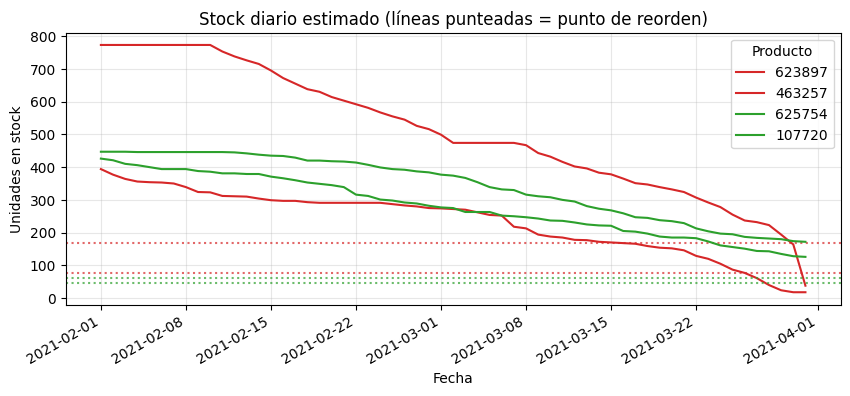

In [62]:
criticos = productos[productos["es_critico"] & productos["tiene_proveedor"]].sort_values("dias_de_stock").index[:2]
sanos = productos[~productos["es_critico"]].sort_values("dias_de_stock", ascending=False).index[:2]

fig, ax = plt.subplots()
for sku in list(criticos) + list(sanos):
    serie = df[df["sku"] == sku].set_index("fecha")["stock_estimado"]
    color = "tab:red" if sku in criticos else "tab:green"
    ax.plot(serie.index, serie.values, color=color, label=f"{sku}")
    ax.axhline(productos.loc[sku, "punto_reorden"], color=color, linestyle=":", alpha=0.7)
ax.set_title("Stock diario estimado (líneas punteadas = punto de reorden)")
ax.set_xlabel("Fecha"); ax.set_ylabel("Unidades en stock"); ax.legend(title="Producto")
fig.autofmt_xdate(); plt.show()

## 8. Cotización: cantidad, opciones de proveedor y recomendación
Para cada producto crítico y **cada proveedor que lo surte**:

- **Cantidad** = `demanda × (plazo del proveedor + días de cobertura) − stock disponible`, redondeada hacia arriba al múltiplo del empaque, y nunca menor al pedido mínimo de ese proveedor.
- **Total** = cantidad × precio unitario.
- **Llega tarde** si los días de stock que quedan son menos que el plazo del proveedor (se agota antes de que llegue).

**Regla de recomendación (explicable):** entre los proveedores que **llegan a tiempo**, el de **menor costo total del pedido**. Si ninguno llega a tiempo, el **más rápido**. El dueño ve todas las opciones y **elige él**; la recomendada solo viene marcada.

In [63]:
filas = []
for sku in productos[productos["es_critico"] & productos["tiene_proveedor"]].index:
    p = productos.loc[sku]
    for _, o in catalogo[catalogo["sku"] == sku].iterrows():
        formula = p["demanda_diaria"] * (o["plazo_dias"] + DIAS_COBERTURA) - p["stock_disponible"]
        redondeada = int(np.ceil(max(formula, 0) / p["empaque"]) * p["empaque"])
        cantidad = max(redondeada, int(o["pedido_minimo_unidades"]))
        filas.append({
            "sku": sku,
            "titulo_producto": p["titulo_producto"],
            "proveedor": o["proveedor"],
            "plazo_dias": o["plazo_dias"],
            "cantidad_formula": round(float(formula), 1),
            "cantidad_a_pedir": cantidad,
            "precio_unitario_cop": o["precio_unitario_cop"],
            "total_cop": cantidad * o["precio_unitario_cop"],
            "llega_tarde": bool(p["dias_de_stock"] < o["plazo_dias"]),
        })
cotizacion = pd.DataFrame(filas)

cotizacion["recomendado"] = False
cotizacion["motivo"] = ""
for sku, grupo in cotizacion.groupby("sku"):
    a_tiempo = grupo[~grupo["llega_tarde"]]
    if len(a_tiempo) > 0:
        idx = a_tiempo.sort_values("total_cop").index[0]
        motivo = "Menor costo total entre los que llegan a tiempo"
    else:
        idx = grupo.sort_values(["plazo_dias", "total_cop"]).index[0]
        motivo = "Ninguno llega a tiempo: el más rápido"
    cotizacion.loc[idx, "recomendado"] = True
    cotizacion.loc[idx, "motivo"] = motivo

print("Productos cotizados:", cotizacion["sku"].nunique(), "| Opciones en total:", len(cotizacion))
print("Recomendaciones por 'ningún proveedor llega a tiempo':",
      int((cotizacion["motivo"] == "Ninguno llega a tiempo: el más rápido").sum()))

Productos cotizados: 11 | Opciones en total: 27
Recomendaciones por 'ningún proveedor llega a tiempo': 1


**Ejemplo de lo que vería el dueño en Telegram** para un producto con varias opciones (⭐ = recomendado):

In [64]:
sku_ejemplo = cotizacion.groupby("sku").size().sort_values(ascending=False).index[0]
ejemplo = cotizacion[cotizacion["sku"] == sku_ejemplo].copy()
print("Producto:", ejemplo["titulo_producto"].iloc[0])
print(f"Stock: {productos.loc[sku_ejemplo, 'stock_actual']} unidades · "
      f"demanda: {productos.loc[sku_ejemplo, 'demanda_diaria']} por día · "
      f"alcanza para {productos.loc[sku_ejemplo, 'dias_de_stock']} días\n")
for _, f in ejemplo.iterrows():
    estrella = "⭐" if f["recomendado"] else "  "
    tarde = "  (llegaría tarde)" if f["llega_tarde"] else ""
    print(f"{estrella} {f['proveedor']:<22} {f['cantidad_a_pedir']:>4} unid. · "
          f"{cop(f['precio_unitario_cop'])} c/u · total {cop(f['total_cop'])} · {f['plazo_dias']} días{tarde}")

Producto: Funda Samsung Galaxy A21s Transparente Con Cristal Templado.
Stock: 13 unidades · demanda: 4.27 por día · alcanza para 3.0 días

⭐ Distribuidora Andina     60 unid. · $31.130 c/u · total $1.867.800 · 2 días
   Importadora Pacífico     66 unid. · $29.780 c/u · total $1.965.480 · 4 días  (llegaría tarde)
   Mayorista Central        78 unid. · $25.710 c/u · total $2.005.380 · 7 días  (llegaría tarde)


**Si el dueño aceptara todas las recomendaciones**, así se agruparía por proveedor (un correo por proveedor):

In [65]:
aceptadas = cotizacion[cotizacion["recomendado"]]
por_proveedor = aceptadas.groupby("proveedor").agg(
    productos=("sku", "nunique"), unidades=("cantidad_a_pedir", "sum"), total_cop=("total_cop", "sum"))
por_proveedor["total_cop"] = por_proveedor["total_cop"].map(cop)
print(por_proveedor)
print("\nTotal de todas las recomendaciones:", cop(aceptadas["total_cop"].sum()))

                      productos  unidades    total_cop
proveedor                                             
Distribuidora Andina         10      1146  $15.835.080
Importadora Pacífico          1       168   $1.231.440

Total de todas las recomendaciones: $17.066.520


## 9. Guardar los resultados y revisar
Estos archivos son los que se cargan a MongoDB en la siguiente fase (uno por colección).

In [66]:
columnas_ventas = ["sku", "fecha", "cantidad_vendida", "minutos_activos", "dias_activos",
                   "precio_mxn", "precio_cop", "dia_atipico", "stock_estimado"]
df[columnas_ventas].to_csv(CARPETA_SALIDA / "ventas_diarias.csv", index=False)
productos.reset_index().to_csv(CARPETA_SALIDA / "productos.csv", index=False)
proveedores.to_csv(CARPETA_SALIDA / "proveedores.csv", index=False)
catalogo.to_csv(CARPETA_SALIDA / "catalogo_proveedores.csv", index=False)
cotizacion.to_csv(CARPETA_SALIDA / "cotizacion.csv", index=False)

for archivo in sorted(CARPETA_SALIDA.glob("*.csv")):
    print(f"{archivo.name:<28} {len(pd.read_csv(archivo)):>5} filas")

catalogo_proveedores.csv       115 filas
cotizacion.csv                  27 filas
productos.csv                   50 filas
proveedores.csv                  3 filas
ventas_diarias.csv            2950 filas


In [67]:
# Revisiones finales: si algo falla, aparece un error claro
assert len(df) == 2950 and df["sku"].nunique() == 50
assert (productos["stock_actual"] > 0).all()
assert (cotizacion.groupby("sku")["recomendado"].sum() == 1).all(), "Cada producto debe tener 1 recomendada"
assert (cotizacion["cantidad_a_pedir"] % cotizacion["sku"].map(productos["empaque"]) == 0).all()
assert not catalogo["sku"].isin([sku_sin_proveedor]).any()
print("Todas las revisiones pasaron.")

Todas las revisiones pasaron.


## Resumen de supuestos (para la defensa)
| Dato | Origen |
|---|---|
| Ventas diarias, precios, minutos activos, nombres | **Reales** (MeLi Data Challenge 2021, México, fundas para celular) |
| Tasa MXN→COP | Fija, 28-oct-2026 (169,5), editable |
| Stock, empaque, mínimo manual, pedidos en camino | **Creados** al azar con semilla fija |
| Proveedores, plazos, precios y mínimos | **Creados**, ficticios, con lógica precio/plazo/mínimo |
| "Hoy" | 31 de marzo de 2021 (último día de los datos) |
| Días de seguridad (2) y de cobertura (14) | Valores de ejemplo, a calibrar con el dueño |
| Umbral de alto valor | No definido aún (lo define el dueño) |